# MWE: lossy photonic parameter-shift rule in Perceval

Minimal benchmark for one Fock transition probability. The circuit is unitary; loss is supplied through Perceval's native `NoiseModel`. Local runs use `SLOS`, but the estimators use finite samples through `Sampler.sample_count`, like a QPU run.


In [1]:
from __future__ import annotations

import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

for candidate in (Path.cwd() / "qgrad", Path.cwd(), Path.cwd().parent / "qgrad"):
    if (candidate / "clements.py").exists():
        sys.path.insert(0, str(candidate))
        break

import perceval as pcvl
from clements import random_parameters, target_value
from qdiff_theo import generate_angles, generate_coefs

SEED = 42
random.seed(SEED)
np.random.seed(SEED)


## Setup

In [2]:
m = 2
input_state = pcvl.BasicState([1, 1])
output_state = pcvl.BasicState([1, 1])
decomposition = random_parameters(m)
target = (0, 1)  # (MZI index, 0=phi, 1=theta)
theta0 = target_value(decomposition, target)

shot_grid = [1_000, 2_000, 5_000, 10_000, 50_000, 100_000]
repeats = 100
losses = [0.1, 0.01, 0.001, 0.0001, 0.00001]

print(f"target theta = {theta0:.4f}")
print(f"PPSR order = {sum(input_state)} photons")
print(f"shots/evaluation = {shot_grid}")
print(f"losses = {np.round(losses, 3).tolist()}")


target theta = 5.9735
PPSR order = 2 photons
shots/evaluation = [1000, 2000, 5000, 10000, 50000, 100000]
losses = [0.1, 0.01, 0.001, 0.0, 0.0]


## Circuit and probability oracles

In [3]:
def circuit(decomp, value=None):
    c = pcvl.Circuit(m)
    for k, (mode, phi, theta) in enumerate(decomp):
        phi = value if target == (k, 0) else phi
        theta = value if target == (k, 1) else theta
        c.add(mode, pcvl.PS(phi=phi))
        c.add(mode, pcvl.BS(convention=pcvl.BSConvention.H))
        c.add(mode, pcvl.PS(phi=theta))
        c.add(mode, pcvl.BS(convention=pcvl.BSConvention.H))
    return c


def processor(theta, loss):
    noise = pcvl.NoiseModel(transmittance=1 - loss)
    p = pcvl.Processor("SLOS", circuit(decomposition, theta), noise=noise)
    p.min_detected_photons_filter(0)
    p.with_input(input_state)
    return p


def prob_exact(theta, loss):
    results = processor(theta, loss).probs(1e-6)["results"]
    return float(results[output_state] if output_state in results else 0.0)


def prob_sampled(theta, loss, nshots):
    sampler = pcvl.algorithm.Sampler(processor(theta, loss), max_shots_per_call=nshots)
    counts = sampler.sample_count(nshots)["results"]
    return float(counts[output_state] if output_state in counts else 0) / nshots


## Circuit visual

A quick visual check of the Clements mesh used in the benchmark.


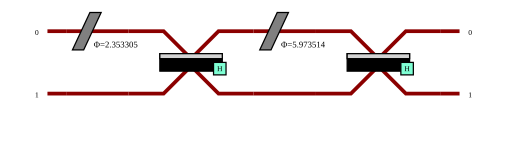

In [4]:
pcvl.pdisplay(circuit(decomposition, theta0))


## Gradient estimators

In [5]:
def ppsr(prob, theta, loss):
    n = sum(input_state)
    return sum(
        c * (prob(theta + s, loss) - prob(theta - s, loss))
        for c, s in zip(generate_coefs(n), generate_angles(n))
    )


def finite_difference(prob, theta, loss, delta=4e-3):
    return (prob(theta + delta, loss) - prob(theta - delta, loss)) / (2 * delta)


## Sweep loss and shots, then plot deviations from the exact gradient

The reference is the exact SLOS PPSR value for each loss. The plotted points are finite-shot estimates, so you can see the actual deviation from the true gradient as both loss and shot budget change.


In [6]:
rows = []
for loss in losses:
    exact_grad = ppsr(prob_exact, theta0, loss)
    for nshots in shot_grid:
        for rep in range(repeats):
            sampled_psr = lambda th, lo, nshots=nshots: prob_sampled(th, lo, nshots)
            sampled_fd = lambda th, lo, nshots=2*nshots: prob_sampled(th, lo, nshots)

            estimates = {
                "FD": finite_difference(sampled_fd, theta0, loss),
                "PSR": ppsr(sampled_psr, theta0, loss)
            }

            for method, estimate in estimates.items():
                rows.append({
                    "loss": loss,
                    "shots": nshots,
                    "rep": rep,
                    "method": method,
                    "estimate": estimate,
                    "exact_grad": exact_grad,
                    "error": estimate - exact_grad,
                    "abs_error": abs(estimate - exact_grad),
                })

df = pd.DataFrame(rows)

df_summary = (
    df.groupby(["loss", "shots", "method"])
    .agg(
        mean_estimate=("estimate", "mean"),
        std_estimate=("estimate", "std"),
        mean_error=("error", "mean"),
        std_error=("error", "std"),
        mean_abs_error=("abs_error", "mean"),
        std_abs_error=("abs_error", "std"),
    )
    .reset_index()
)


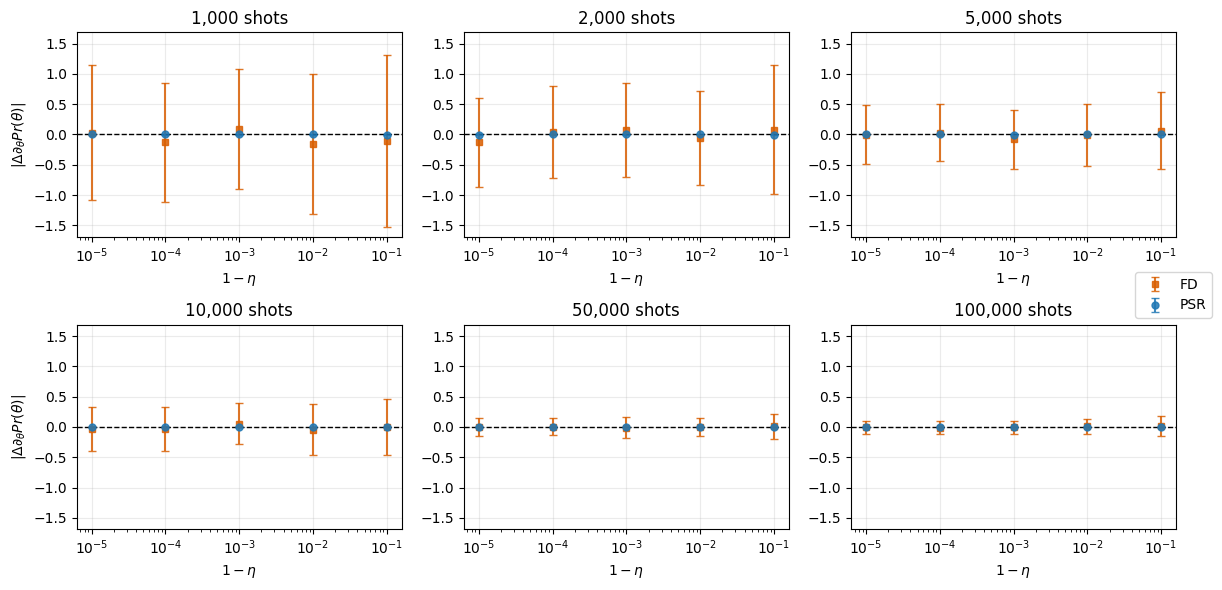

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=False)
axes = axes.flatten()

markers = {"FD": "s", "PSR": "o"}
colors = {"PSR": "#1f77b4", "FD": "#d95f02"}

ymax = 1e-12
for nshots in shot_grid:
    part = df[df["shots"] == nshots]
    avg = part.groupby(["loss", "method"])["error"].agg(["mean", "std"])
    ymax = max(ymax, (avg["mean"].abs() + avg["std"].fillna(0)).max())

for ax, nshots in zip(axes, shot_grid):
    part = df[df["shots"] == nshots]

    avg = (
        part.groupby(["loss", "method"])["error"]
        .agg(["mean", "std"])
        .reset_index()
    )

    for method in ["FD", "PSR"]:
        group = avg[avg["method"] == method]

        ax.errorbar(
            group["loss"],
            group["mean"],
            yerr=group["std"],
            fmt=markers[method],
            markersize=5,
            color=colors[method],
            alpha=0.85,
            capsize=3,
            label=method,
        )

    ax.axhline(0.0, color="black", linewidth=1, linestyle="--")

    ax.set_ylim(-1.1 * ymax, 1.1 * ymax)
    ax.set_xscale("log")

    ax.set_title(f"{nshots:,} shots")
    ax.set_xlabel(r"$1 - \eta$")
    ax.grid(alpha=0.25)

for ax in axes:
    ax.set_ylabel("")
for ax in axes[::3]:
    ax.set_ylabel(r"$|\Delta\partial_\theta Pr(\theta)|$")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center right", bbox_to_anchor=(1.02, 0.5))

fig.tight_layout()
fig.savefig("gradient_deviations.pdf", bbox_inches="tight")
plt.show()